In [1]:
import re
import string
import pickle
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import nltk
for resource, pkg in [
    ("tokenizers/punkt", "punkt"),
    ("tokenizers/punkt_tab", "punkt_tab"),
    ("corpora/stopwords", "stopwords"),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords as nltk_stopwords
from nltk.tokenize import word_tokenize

import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Load artifacts ────────────────────────────────────────────
MODEL_PATH    = Path("../saved_model.pth")
WORD2IDX_PATH = Path("../models/word2idx.pkl")
LABEL_PATH    = Path("../models/label_encoder.pkl")

for p in [MODEL_PATH, WORD2IDX_PATH, LABEL_PATH]:
    assert p.exists(), f"Missing: {p} — run train.ipynb first!"

with open(WORD2IDX_PATH, "rb") as f:
    WORD2IDX: Dict[str, int] = pickle.load(f)
with open(LABEL_PATH, "rb") as f:
    enc = pickle.load(f)
    IDX2STR: Dict[int, str] = enc["idx2str"]

VOCAB_SIZE  = len(WORD2IDX)
NUM_CLASSES = len(IDX2STR)
PAD_IDX, UNK_IDX = 0, 1
MAX_SEQ_LEN = 512

print(f"✅ Vocab: {VOCAB_SIZE:,} | Classes: {list(IDX2STR.values())}")

✅ Vocab: 17,196 | Classes: ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']


In [2]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_size=128,
                 num_layers=2, num_classes=5, lstm_dropout=0.5,
                 fc_dropout=0.3, bidirectional=True, pad_idx=0):
        super().__init__()
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers,
                            bidirectional=bidirectional, batch_first=True,
                            dropout=lstm_dropout if num_layers > 1 else 0.0)
        dirs = 2 if bidirectional else 1
        self.dropout1 = nn.Dropout(lstm_dropout)
        self.fc1      = nn.Linear(hidden_size * dirs, hidden_size)
        self.relu     = nn.ReLU()
        self.dropout2 = nn.Dropout(fc_dropout)
        self.fc2      = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        emb = self.embedding(x)
        _, (h, _) = self.lstm(emb)
        h = torch.cat((h[-2], h[-1]), dim=1) if self.bidirectional else h[-1]
        return self.fc2(self.dropout2(self.relu(self.fc1(self.dropout1(h)))))


model = BiLSTMClassifier(VOCAB_SIZE, num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()
print("✅ Model loaded.")

✅ Model loaded.


In [3]:
STOP_WORDS = set(nltk_stopwords.words("english"))

def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    return re.sub(r"\s+", " ", text).strip()

def preprocess(text: str) -> List[str]:
    tokens = word_tokenize(clean_text(text))
    return [t for t in tokens if t not in STOP_WORDS and len(t) > 1]

def text_to_indices(tokens: List[str], max_len: int) -> List[int]:
    indices = [WORD2IDX.get(t, UNK_IDX) for t in tokens[:max_len]]
    return indices + [PAD_IDX] * (max_len - len(indices))


@torch.no_grad()
def predict(text: str) -> Dict:
    """Classify a news article.

    Args:
        text: Raw article string.

    Returns:
        Dict with 'predicted_category', 'confidence', 'all_scores'.
    """
    model.eval()
    tokens  = preprocess(text)
    indices = text_to_indices(tokens, MAX_SEQ_LEN)
    tensor  = torch.tensor([indices], dtype=torch.long).to(DEVICE)
    probs   = F.softmax(model(tensor), dim=1).squeeze()

    pred_idx   = probs.argmax().item()
    pred_class = IDX2STR[pred_idx]
    confidence = probs[pred_idx].item() * 100
    all_scores = {IDX2STR[i]: round(probs[i].item() * 100, 2) for i in range(NUM_CLASSES)}

    return {"predicted_category": pred_class, "confidence": round(confidence, 2), "all_scores": all_scores}


print("✅ predict() function ready.")

✅ predict() function ready.


In [4]:
ARTICLE = """
Apple unveiled its newest AI-powered smartphone with a groundbreaking neural engine chip
that delivers 40% faster machine learning performance than its predecessor.
"""

result = predict(ARTICLE)

print(f"\n{'='*55}")
print(f"  📰 Input (truncated): {ARTICLE.strip()[:80]}...")
print(f"{'='*55}")
print(f"  🏆 Predicted : {result['predicted_category']}")
print(f"  📊 Confidence: {result['confidence']:.1f}%")
print(f"{'='*55}")
print("\n  All class scores:")
for cat, score in sorted(result["all_scores"].items(), key=lambda x: -x[1]):
    bar = "█" * int(score / 4)
    print(f"   {cat:<15} {bar:<25} {score:>5.1f}%")


  📰 Input (truncated): Apple unveiled its newest AI-powered smartphone with a groundbreaking neural eng...
  🏆 Predicted : Technology
  📊 Confidence: 99.8%

  All class scores:
   Technology      ████████████████████████   99.8%
   Entertainment                               0.1%
   Business                                    0.1%
   Politics                                    0.0%
   Sports                                      0.0%


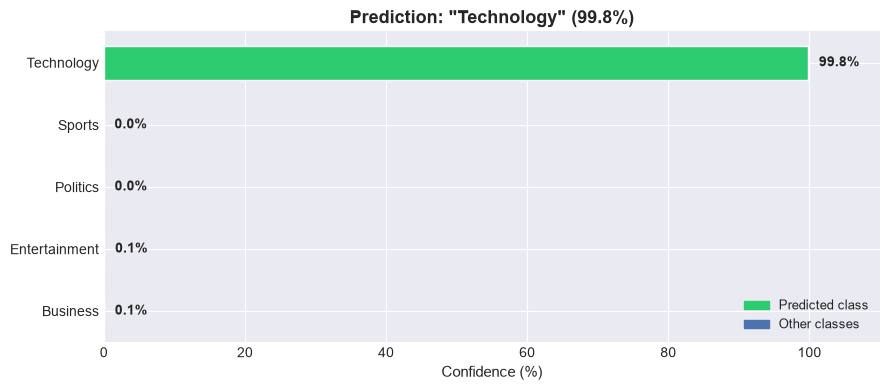

In [5]:
plt.style.use("seaborn-v0_8-darkgrid")
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

cats   = list(IDX2STR[i] for i in range(NUM_CLASSES))
scores = [result["all_scores"][c] for c in cats]
bar_colors = [
    "#2ecc71" if c == result["predicted_category"] else "#4C72B0"
    for c in cats
]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(cats, scores, color=bar_colors, edgecolor="white", height=0.55)
ax.set_xlim(0, 110)
ax.set_xlabel("Confidence (%)", fontsize=11)
ax.set_title(f'Prediction: "{result["predicted_category"]}" ({result["confidence"]:.1f}%)',
             fontsize=13, fontweight="bold")
for bar, score in zip(bars, scores):
    ax.text(score + 1.5, bar.get_y() + bar.get_height() / 2,
            f"{score:.1f}%", va="center", fontsize=10, fontweight="bold")

predicted_patch = mpatches.Patch(color="#2ecc71", label="Predicted class")
other_patch     = mpatches.Patch(color="#4C72B0", label="Other classes")
ax.legend(handles=[predicted_patch, other_patch], loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("../models/prediction_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# ✏️ Add your own articles to this list
ARTICLES = [
    "Apple unveiled its newest AI-powered smartphone with a groundbreaking chip architecture.",
    "The Prime Minister announced new economic policies aimed at reducing inflation and boosting growth.",
    "Manchester United secured a dramatic 3-2 victory in the Champions League final against Bayern Munich.",
    "The Hollywood awards season kicked off with major nominations for blockbuster films.",
    "Global stock markets tumbled as oil prices surged amid supply chain disruptions.",
]

rows = []
for article in ARTICLES:
    r = predict(article)
    rows.append({
        "Article": article[:70] + "...",
        "Predicted": r["predicted_category"],
        "Confidence": f"{r['confidence']:.1f}%",
    })

results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False))
results_df

                                                                  Article     Predicted Confidence
Apple unveiled its newest AI-powered smartphone with a groundbreaking ...    Technology      99.8%
The Prime Minister announced new economic policies aimed at reducing i...      Business      83.0%
Manchester United secured a dramatic 3-2 victory in the Champions Leag...        Sports     100.0%
The Hollywood awards season kicked off with major nominations for bloc... Entertainment      99.9%
Global stock markets tumbled as oil prices surged amid supply chain di...      Business     100.0%


,Article,Predicted,Confidence
0,Apple unveiled its newest AI-powered smartphon...,Technology,99.8%
1,The Prime Minister announced new economic poli...,Business,83.0%
2,Manchester United secured a dramatic 3-2 victo...,Sports,100.0%
3,The Hollywood awards season kicked off with ma...,Entertainment,99.9%
4,Global stock markets tumbled as oil prices sur...,Business,100.0%
